Load all downloaded seasons into one `matches` table.

In [1]:
import os, sys
os.chdir("..")
sys.path.append(".")

from src.data_loader import load_matches
matches = load_matches()

1617 380
1718 380
1819 380
1920 380
2021 380
2122 380
2223 380
2324 380
2425 380
2526 380
2627 50


/home/alexrohjak/code/premier-league-predictor/src/data_loader.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matches["Season"] = season
/home/alexrohjak/code/premier-league-predictor/src/data_loader.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matches["Season"] = season
/home/alexrohjak/code/premier-league-predictor/src/data_loader.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at

Check how often each result happens (H = home win, D = draw, A = away win).

In [3]:
matches["FTR"].value_counts(normalize=True)

FTR
H    0.445195
A    0.321299
D    0.233506
Name: proportion, dtype: float64

Reshape matches into one row per team per match, with the points that team earned.

In [4]:
import pandas as pd
matches["Date"] = pd.to_datetime(matches["Date"], dayfirst = True, format = "mixed")

home = pd.DataFrame({
      "Date": matches["Date"],
      "Team": matches["HomeTeam"],
      "Home": True,
      "Points": matches["FTR"].map({"H": 3, "D": 1, "A": 0}),
  })  

away = pd.DataFrame({
      "Date": matches["Date"],
      "Team": matches["AwayTeam"],
      "Home": False,
      "Points": matches["FTR"].map({"H": 0, "D": 1, "A": 3}),
  })  

team_matches = pd.concat([home, away]).sort_values("Date")
team_matches[team_matches["Team"] == "Liverpool"].tail(5)

,Date,Team,Home,Points
3808,2026-08-23,Liverpool,False,1
3811,2026-08-29,Liverpool,True,1
3820,2026-09-04,Liverpool,False,3
3834,2026-09-12,Liverpool,True,1
3846,2026-09-20,Liverpool,False,3


Compute each team's form: average points over its previous 5 matches (excluding the current one).

In [5]:
team_matches["Form"] = (
    team_matches.groupby("Team")["Points"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods = 1).mean())
)
team_matches[team_matches["Team"] == "Tottenham"].tail(6)

,Date,Team,Home,Points,Form
3798,2026-05-24,Tottenham,True,3,1.6
3805,2026-08-22,Tottenham,False,0,2.0
3814,2026-08-29,Tottenham,True,0,1.4
3826,2026-09-05,Tottenham,False,1,0.8
3835,2026-09-12,Tottenham,True,1,0.8
3841,2026-09-19,Tottenham,True,0,1.0


Attach the home team's and away team's form back onto each match.

In [6]:
matches["HomeForm"] = team_matches[team_matches["Home"]]["Form"]
matches["AwayForm"] = team_matches[~team_matches["Home"]]["Form"]

/tmp/ipykernel_39885/3640862748.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matches["HomeForm"] = team_matches[team_matches["Home"]]["Form"]
/tmp/ipykernel_39885/3640862748.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matches["AwayForm"] = team_matches[~team_matches["Home"]]["Form"]


Spot-check the form values for one match day.

In [6]:
matches[matches["Date"] == "2026-09-19"][["HomeTeam", "AwayTeam", "FTR", "HomeForm", "AwayForm"]]

,HomeTeam,AwayTeam,FTR,HomeForm,AwayForm
3841,Tottenham,Aston Villa,A,1.0,0.8
3842,Brighton,Arsenal,H,1.4,3.0
3843,Everton,Ipswich,H,1.2,1.2
3844,Newcastle,Hull,H,1.0,1.6
3845,Nott'm Forest,Coventry,A,1.2,0.0


Count matches with missing form values.

In [7]:
matches[["HomeForm", "AwayForm"]].isna().sum()

HomeForm    16
AwayForm    19
dtype: int64

Show which matches are missing form (teams with no earlier matches in the data).

In [8]:
missing = matches[matches["HomeForm"].isna() | matches["AwayForm"].isna()]
missing[["Date", "HomeTeam", "AwayTeam", "HomeForm", "AwayForm"]]

,Date,HomeTeam,AwayTeam,HomeForm,AwayForm
0,2016-08-13,Burnley,Swansea,NaN,NaN
1,2016-08-13,Crystal Palace,West Brom,NaN,NaN
2,2016-08-13,Everton,Tottenham,NaN,NaN
3,2016-08-13,Hull,Leicester,NaN,NaN
4,2016-08-13,Man City,Sunderland,NaN,NaN
5,2016-08-13,Middlesbrough,Stoke,NaN,NaN
6,2016-08-13,Southampton,Watford,NaN,NaN
7,2016-08-14,Arsenal,Liverpool,NaN,NaN
8,2016-08-14,Bournemouth,Man United,NaN,NaN
9,2016-08-15,Chelsea,West Ham,NaN,NaN


Drop matches where both teams lack form, and fill the remaining gaps with 0.79.

In [ ]:
both_missing = matches["HomeForm"].isna() & matches["AwayForm"].isna()
matches = matches[~both_missing]

matches["HomeForm"] = matches["HomeForm"].fillna(0.79)
matches["AwayForm"] = matches["AwayForm"].fillna(0.79)

HomeForm    0
AwayForm    0
dtype: int64

Train a logistic regression on form (up to 2024/25) and test it on 2025/26.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

features = ["HomeForm", "AwayForm"]

train = matches[matches["Season"] <= "2425"]
test  = matches[matches["Season"] == "2526"]
  
model = LogisticRegression()
model.fit(train[features], train["FTR"])

predictions = model.predict(test[features])
print("Train:", len(train), "Test:", len(test))
print("Accuracy:", accuracy_score(test["FTR"], predictions))

pd.Series(predictions).value_counts()


Train: 3410 Test: 380
Accuracy: 0.4342105263157895


H    258
A    122
Name: count, dtype: int64

Show the actual result distribution in the test season, to compare against the model.

In [12]:
test["FTR"].value_counts(normalize=True)

FTR
H    0.426316
A    0.300000
D    0.273684
Name: proportion, dtype: float64

Define the Elo helpers: expected home score and the rating change after a match.

In [14]:
def expected_score(home_rating, away_rating):
    return 1 / (1 + 10 ** ((away_rating - home_rating) / 400))

def rating_change(home_rating, away_rating, result, k=20):
    return k * (result - expected_score(home_rating, away_rating))

Sanity check: expected score for a 1700-rated team against a 1400-rated team.

In [15]:
print(expected_score(1700, 1400))

0.8490204427886767


Sanity check: the rating change when a 1700 team draws with a 1650 team.

In [21]:
print(rating_change(1700, 1650, 0.5))

-1.429262348167628


Compute each team's Elo rating before every match, giving promoted teams the relegated teams' average rating.

In [22]:
matches = matches.sort_values("Date")

home_elo = []
away_elo = []
ratings = {}
previous_teams = None

for season in matches["Season"].unique():
    season_matches = matches[matches["Season"] == season]
    teams = set(season_matches["HomeTeam"]) | set(season_matches["AwayTeam"])

    if previous_teams is None:
        for team in teams:
            ratings[team] = 1500
    else:
        relegated = previous_teams - teams
        promoted = teams - previous_teams
        start = sum(ratings[t] for t in relegated) / len(relegated)
        print(season, "relegated:", sorted(relegated), "promoted:", sorted(promoted), "start:", start)            
        for team in promoted:
            ratings[team] = start

    for _, row in season_matches.iterrows():
          home = row["HomeTeam"]
          away = row["AwayTeam"]
          h = ratings[home]
          a = ratings[away]
          
          home_elo.append(h)   
          away_elo.append(a)

          result = {"H": 1, "D": 0.5, "A": 0}[row["FTR"]]
          change = rating_change(h, a, result)
          ratings[home] = h + change
          ratings[away] = a - change

    previous_teams = teams
 
matches["HomeElo"] = home_elo    
matches["AwayElo"] = away_elo
matches["EloDiff"] = matches["HomeElo"] - matches["AwayElo"]

1718 relegated: ['Hull', 'Middlesbrough', 'Sunderland'] promoted: ['Brighton', 'Huddersfield', 'Newcastle'] start: 1396.9529496915231
1819 relegated: ['Stoke', 'Swansea', 'West Brom'] promoted: ['Cardiff', 'Fulham', 'Wolves'] start: 1407.0342791682758
1920 relegated: ['Cardiff', 'Fulham', 'Huddersfield'] promoted: ['Aston Villa', 'Norwich', 'Sheffield United'] start: 1342.6467377028985
2021 relegated: ['Bournemouth', 'Norwich', 'Watford'] promoted: ['Fulham', 'Leeds', 'West Brom'] start: 1362.8933101750154
2122 relegated: ['Fulham', 'Sheffield United', 'West Brom'] promoted: ['Brentford', 'Norwich', 'Watford'] start: 1352.1373014935582
2223 relegated: ['Burnley', 'Norwich', 'Watford'] promoted: ['Bournemouth', 'Fulham', "Nott'm Forest"] start: 1342.8087533859853
2324 relegated: ['Leeds', 'Leicester', 'Southampton'] promoted: ['Burnley', 'Luton', 'Sheffield United'] start: 1384.2577236267916
2425 relegated: ['Burnley', 'Luton', 'Sheffield United'] promoted: ['Ipswich', 'Leicester', 'Sou

/tmp/ipykernel_54576/1416750378.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matches["HomeElo"] = home_elo
/tmp/ipykernel_54576/1416750378.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matches["AwayElo"] = away_elo
/tmp/ipykernel_54576/1416750378.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = fr

Summarise and plot every team's Elo rating through the 2024/25 season.

                 Start     End  Change
Team                                  
Liverpool       1681.0  1689.0     9.0
Man City        1775.0  1689.0   -86.0
Arsenal         1705.0  1677.0   -28.0
Chelsea         1561.0  1590.0    30.0
Aston Villa     1571.0  1584.0    13.0
Newcastle       1553.0  1569.0    17.0
Brighton        1492.0  1542.0    50.0
Crystal Palace  1482.0  1528.0    47.0
Brentford       1449.0  1503.0    54.0
Nott'm Forest   1392.0  1502.0   110.0
Everton         1462.0  1499.0    37.0
Bournemouth     1435.0  1492.0    56.0
Fulham          1446.0  1486.0    40.0
Man United      1564.0  1472.0   -93.0
West Ham        1473.0  1447.0   -26.0
Wolves          1435.0  1442.0     7.0
Tottenham       1545.0  1433.0  -113.0
Leicester       1325.0  1308.0   -17.0
Ipswich         1325.0  1298.0   -27.0
Southampton     1321.0  1251.0   -69.0


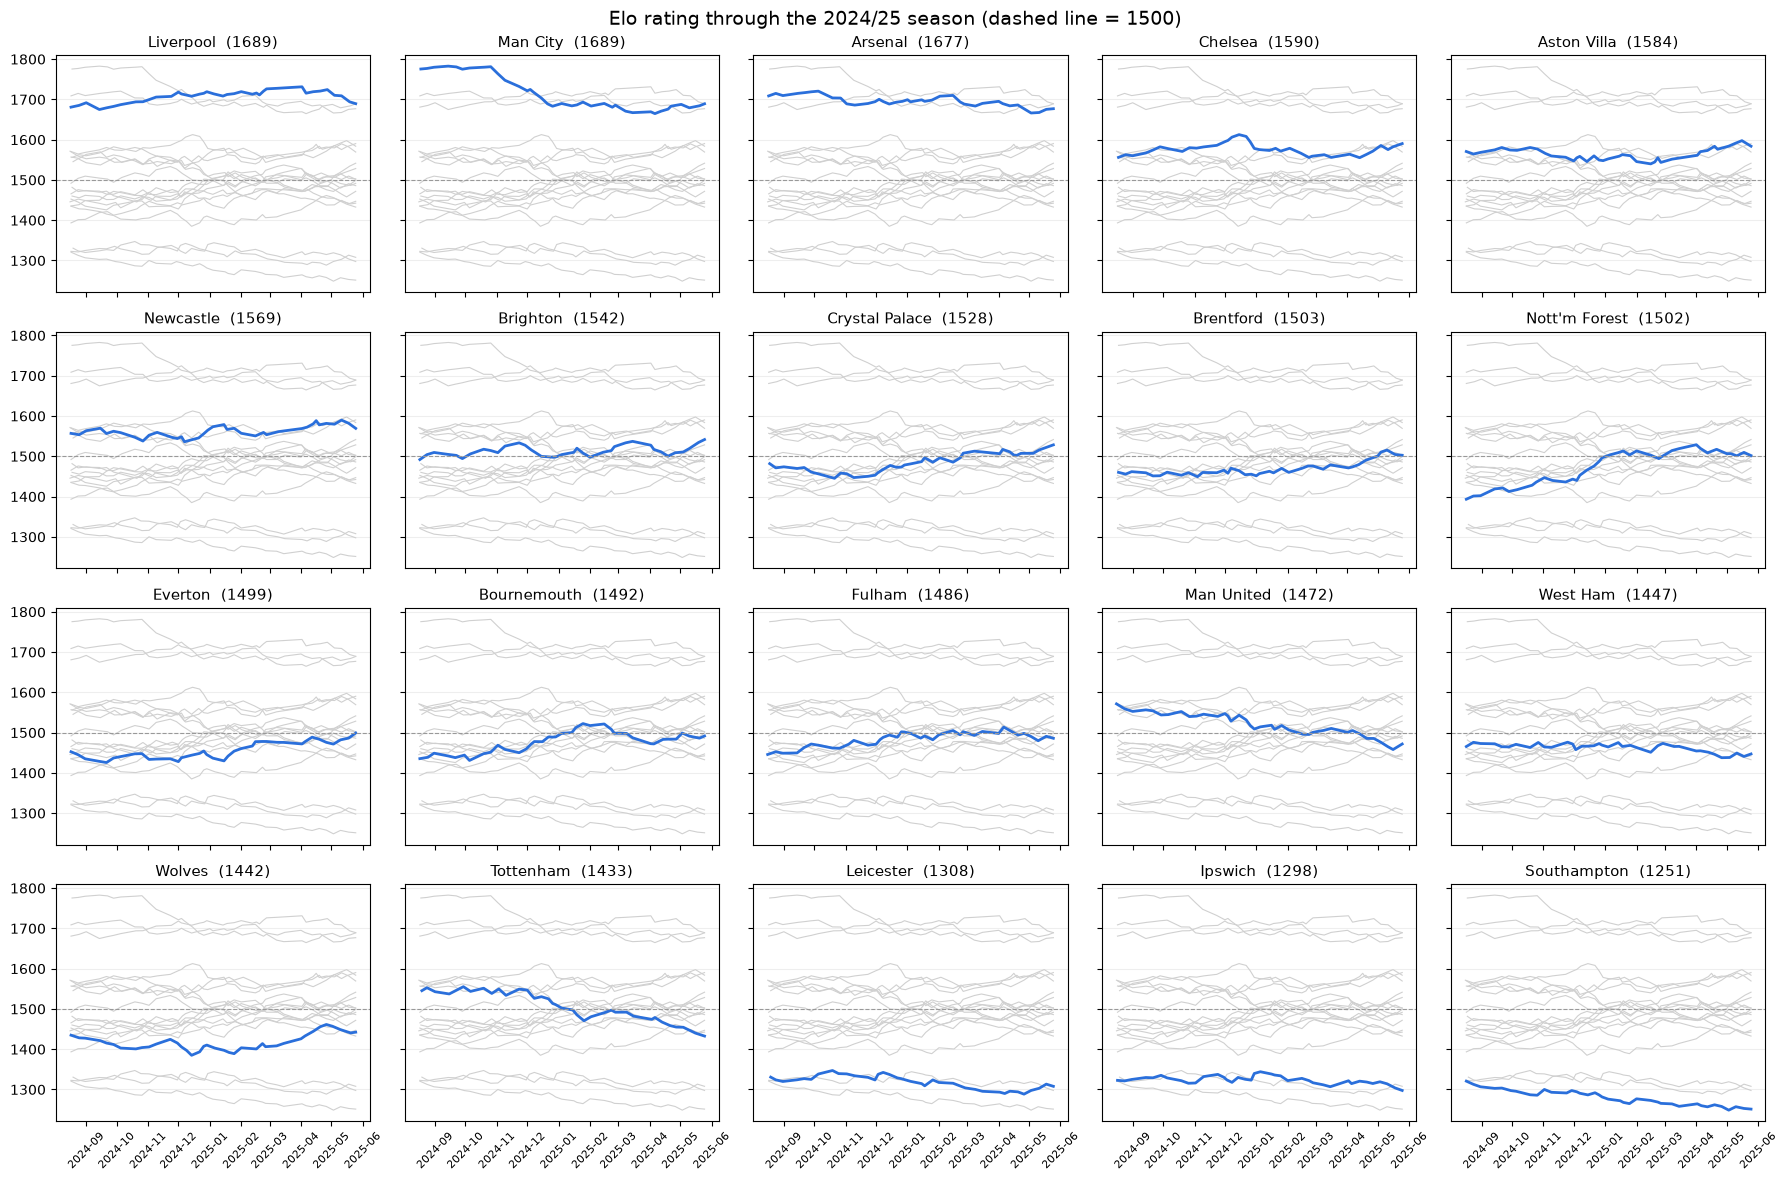

In [28]:
import matplotlib.pyplot as plt

season = matches[matches["Season"] == "2425"].copy()

# Rating AFTER each match = rating before + the change from that match
result = season["FTR"].map({"H": 1, "D": 0.5, "A": 0})
season["Change"] = [rating_change(h, a, r) for h, a, r in zip(season["HomeElo"], season["AwayElo"], result)]
 
elo_history = pd.concat([
    pd.DataFrame({"Date": season["Date"], "Team": season["HomeTeam"], "Elo": season["HomeElo"] + season["Change"]}),
    pd.DataFrame({"Date": season["Date"], "Team": season["AwayTeam"], "Elo": season["AwayElo"] - season["Change"]}),
]).sort_values("Date")
 
# Start and end of season per team
start = pd.concat([
    season[["HomeTeam", "HomeElo"]].set_axis(["Team", "Elo"], axis=1),
    season[["AwayTeam", "AwayElo"]].set_axis(["Team", "Elo"], axis=1),
]).groupby("Team")["Elo"].first()
end = elo_history.groupby("Team")["Elo"].last()

summary = pd.DataFrame({"Start": start, "End": end})
summary["Change"] = summary["End"] - summary["Start"]
summary = summary.sort_values("End", ascending=False).round(0)
print(summary)
  
# One small chart per team, ordered by final rating
teams = summary.index
fig, axes = plt.subplots(4, 5, figsize=(18, 12), sharex=True, sharey=True)
for ax, team in zip(axes.flat, teams):
    for other in teams: 
        other_history = elo_history[elo_history["Team"] == other]
        ax.plot(other_history["Date"], other_history["Elo"], color="#d0d0d0", linewidth=0.8)
    team_history = elo_history[elo_history["Team"] == team]
    ax.plot(team_history["Date"], team_history["Elo"], color="#2a6fdb", linewidth=2)
    ax.set_title(f"{team}  ({summary.loc[team, 'End']:.0f})", fontsize=11)
    ax.axhline(1500, color="#999999", linewidth=0.8, linestyle="--")
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.grid(axis="y", color="#eeeeee")
fig.suptitle("Elo rating through the 2024/25 season (dashed line = 1500)", fontsize=14)
fig.tight_layout()
plt.show()